In [14]:
from google.colab import drive
import os, subprocess

drive.mount("/content/drive")

work = "/content/drive/MyDrive/computer_vision"
os.chdir(work)

data_dir = "/root/crack-detect/data"
if not os.path.exists(data_dir + "/Bridge_Crack_Image"):
    os.makedirs(data_dir, exist_ok=True)
    subprocess.run(["unzip", "-q", work + "/archive.zip", "Bridge_Crack_Image/*", "-d", data_dir], check=True)

print(os.getcwd(), os.listdir(data_dir))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/computer_vision ['Bridge_Crack_Image']


In [15]:
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, precision_recall_curve

df = pd.read_csv("manifest.csv")
device = "cuda" if torch.cuda.is_available() else "cpu"

SIZE = 128
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class CrackDS(Dataset):
    def __init__(self, d, tf):
        self.p = d.path.tolist()
        self.y = d.label.tolist()
        self.tf = tf
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

model = models.resnet18()
model.fc = nn.Linear(model.fc.in_features, 2)
model.load_state_dict(torch.load("crack_resnet18.pt", map_location=device))
model = model.to(device).eval()

def predict(d):
    dl = DataLoader(CrackDS(d, eval_tf), batch_size=64, shuffle=False, num_workers=2)
    probs, ys = [], []
    with torch.no_grad():
        for x, y in dl:
            probs += F.softmax(model(x.to(device)), dim=1)[:, 1].cpu().tolist()
            ys += y.tolist()
    return np.array(probs), np.array(ys)

val_p, val_y = predict(df[df.split == "val"])
test_p, test_y = predict(df[df.split == "test"])

In [16]:
prec, rec, thr = precision_recall_curve(val_y, val_p)
f1s = 2 * prec * rec / (prec + rec + 1e-8)
threshold = float(thr[np.argmax(f1s[:-1])])
print("threshold from validation:", threshold)
json.dump({"threshold": threshold}, open("threshold.json", "w"))

pred = (test_p >= threshold).astype(int)
print(classification_report(test_y, pred, target_names=["no crack", "crack"], digits=4))
print("ROC AUC:", roc_auc_score(test_y, test_p))

threshold from validation: 0.925055205821991
              precision    recall  f1-score   support

    no crack     0.9989    0.9911    0.9950      4400
       crack     0.9385    0.9917    0.9643       600

    accuracy                         0.9912      5000
   macro avg     0.9687    0.9914    0.9797      5000
weighted avg     0.9916    0.9912    0.9913      5000

ROC AUC: 0.9982446969696968


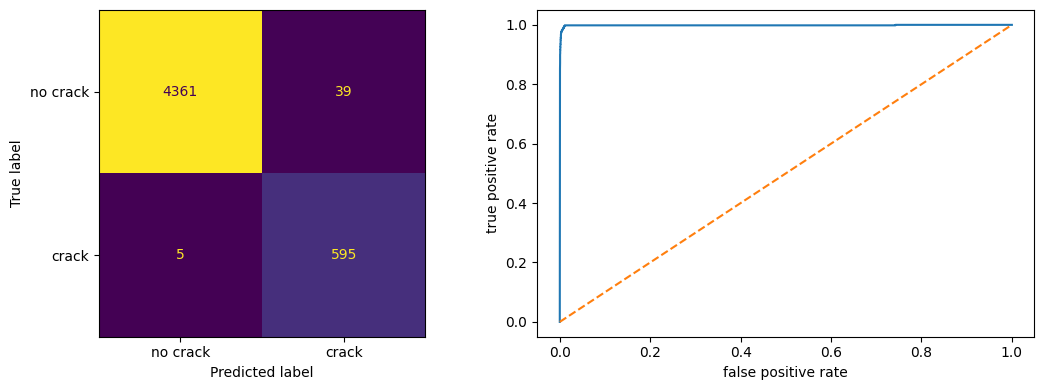

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(test_y, pred), display_labels=["no crack", "crack"]).plot(ax=ax[0], colorbar=False)
fpr, tpr, _ = roc_curve(test_y, test_p)
ax[1].plot(fpr, tpr)
ax[1].plot([0, 1], [0, 1], "--")
ax[1].set_xlabel("false positive rate")
ax[1].set_ylabel("true positive rate")
plt.tight_layout()
plt.show()

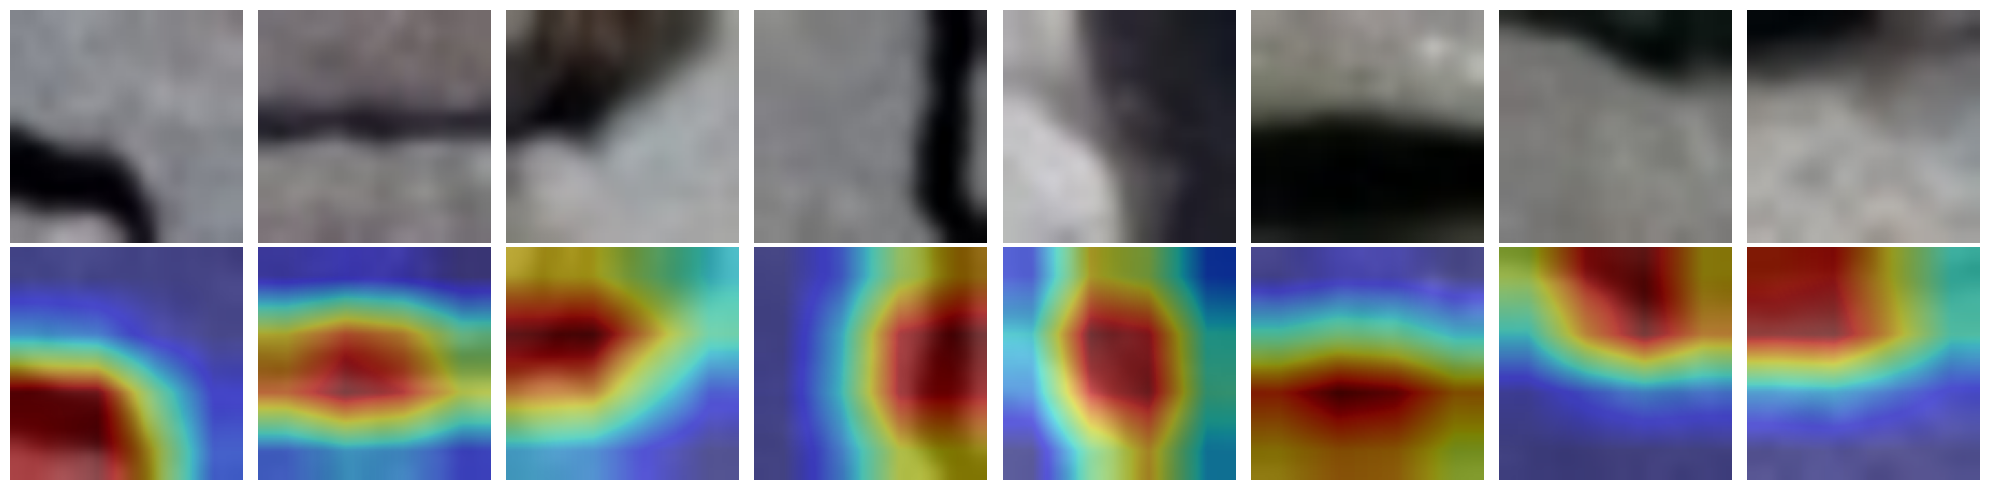

In [18]:
model.layer4._forward_hooks.clear()

class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.a = None
        self.g = None
        self.handle = layer.register_forward_hook(self.fwd)
    def fwd(self, m, i, o):
        if o.requires_grad:
            self.a = o
            o.register_hook(lambda g: setattr(self, "g", g))
    def __call__(self, x, cls=1):
        self.model.zero_grad()
        out = self.model(x)
        out[0, cls].backward()
        w = self.g.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self.a).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0].detach().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    def remove(self):
        self.handle.remove()

cam_fn = GradCAM(model, model.layer4)
test_df = df[df.split == "test"].reset_index(drop=True)
idx = np.where((test_y == 1) & (test_p >= threshold))[0][:8]

fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for col, i in enumerate(idx):
    img = Image.open(test_df.path[i]).convert("RGB").resize((SIZE, SIZE))
    x = eval_tf(img).unsqueeze(0).to(device)
    cam = cam_fn(x)
    axes[0, col].imshow(img)
    axes[0, col].axis("off")
    axes[1, col].imshow(img)
    axes[1, col].imshow(cam, cmap="jet", alpha=0.5)
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

cam_fn.remove()
model.layer4._forward_hooks.clear()

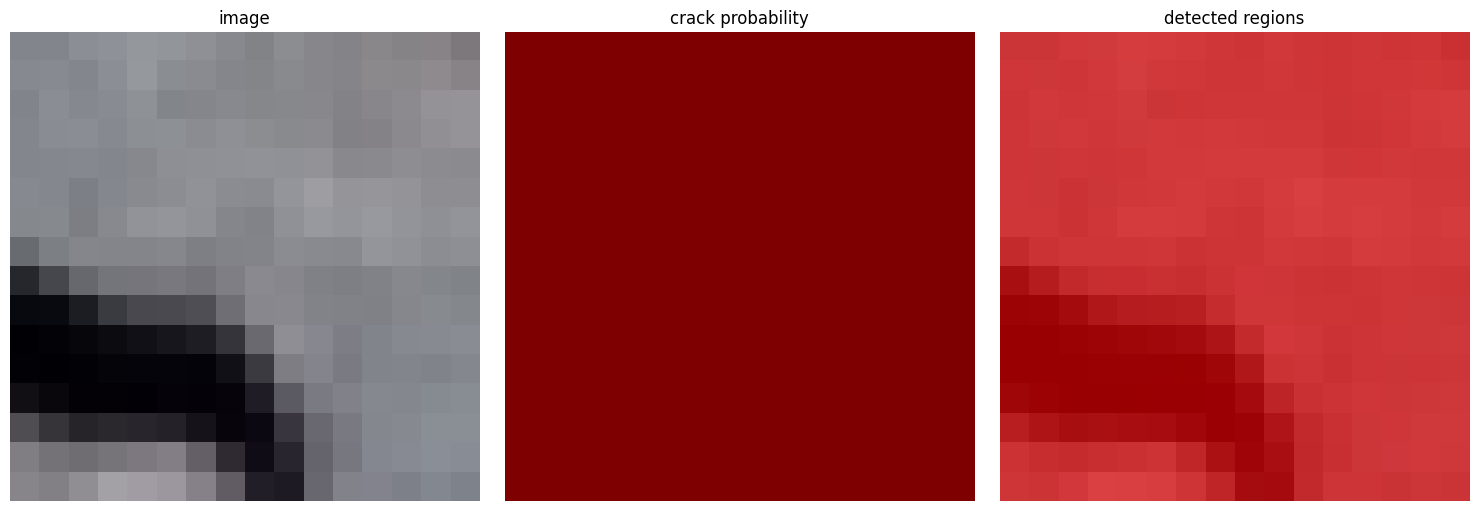

In [19]:
def tile_heatmap(img_path, tile=128, stride=64, bs=32):
    img = Image.open(img_path).convert("RGB")
    W, H = img.size
    tile = min(tile, W, H)
    xs = list(range(0, W - tile + 1, stride))
    ys = list(range(0, H - tile + 1, stride))
    if xs[-1] + tile < W:
        xs.append(W - tile)
    if ys[-1] + tile < H:
        ys.append(H - tile)
    coords = [(x, y) for y in ys for x in xs]
    acc = np.zeros((H, W), dtype=np.float32)
    cnt = np.zeros((H, W), dtype=np.float32)
    for s in range(0, len(coords), bs):
        chunk = coords[s:s + bs]
        batch = torch.stack([eval_tf(img.crop((x, y, x + tile, y + tile))) for x, y in chunk]).to(device)
        with torch.no_grad():
            p = F.softmax(model(batch), dim=1)[:, 1].cpu().numpy()
        for (x, y), pv in zip(chunk, p):
            acc[y:y + tile, x:x + tile] += pv
            cnt[y:y + tile, x:x + tile] += 1
    return np.array(img), acc / np.maximum(cnt, 1)

sample_path = test_df[test_df.label == 1].path.iloc[0]
img, heat = tile_heatmap(sample_path)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img)
ax[0].set_title("image")
ax[1].imshow(heat, cmap="jet", vmin=0, vmax=1)
ax[1].set_title("crack probability")
ax[2].imshow(img)
ax[2].imshow(np.ma.masked_where(heat < threshold, heat), cmap="autumn", alpha=0.6)
ax[2].set_title("detected regions")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()